# Demanda eléctrica por área del SEIN: explicabilidad, privacidad y seguridad del modelo

**TB1 · Metodología para Data Science (1ACC0240) · UPC · ciclo 2026-2 · Grupo 3**

Notebook 05 del caso peruano: **qué mira el modelo de la app y por qué pronostica lo que pronostica**. Los notebooks
02 y 03 midieron cuánto acierta y la importancia por permutación (cuánto empeora el error al perder una variable).
Aquí se abre la caja con **SHAP**: cuánto empuja cada variable cada pronóstico, en MW, de forma global (en miles de
periodos) y local (en tres casos con sentido para el operador). Cierra con la privacidad y la seguridad del modelo.

**Reglas de esta corrida**

- **El modelo es el de la app:** los XGBoost globales de `modelos/sein/app/`, con los hiperparámetros del notebook 02,
  entrenados con 2016-2025 (`app/backend/pronosticador_real.py`). Se explica la variante **M3** (demanda, calendario,
  clima, El Niño y fallas) a **1 h** y a **24 h**, porque es la que tiene todas las familias de variables.
- **2025 es dentro de muestra para este modelo y 2026 no.** La app se entrenó con 2025 adentro, así que en 2025 SHAP
  describe lo que el modelo aprendió; en la prueba de 2026 describe cómo razona con datos que nunca vio. Las
  conclusiones se apoyan en 2026.
- **Una muestra, no todo el conjunto.** SHAP exacto sobre 800 árboles de profundidad 10 cuesta unos 5 ms por periodo
  en una laptop: se usan 2,000 periodos por área, año y horizonte (24,000 en total), elegidos al azar con semilla fija.
  Los casos locales se explican completos.
- **No se elige ni se reentrena nada.** Todo es lectura del modelo ya entrenado; las cifras de error de los
  notebooks 02 a 04 no cambian.

| Paso | Qué hace |
|---|---|
| 1. Datos y modelos | El pipeline reproducible y los modelos de la app, con su error en 2025 y 2026 |
| 2. SHAP en un modelo en razón | Cómo se lee: del árbol (razón) a MW, con la escala de cada periodo |
| 3. Importancia global | Por familia de variables y las 15 variables que más mueven el pronóstico |
| 4. Beeswarm | Hacia dónde empuja cada variable según su valor |
| 5. Dependencia | Las tres variables principales, una por una |
| 6. Frente a la permutación | Por qué SHAP y la importancia por permutación del notebook 02 no dicen lo mismo |
| 7. Tres casos locales | Un pico bien pronosticado, el peor error de 2026 y un día de El Niño |
| 8. Privacidad y seguridad | Para el Entregable 8: datos, licencias, riesgos en operación y controles |
| 9. Guardar | Las tablas, para el paper y la app |

Corre en unos cinco minutos en una laptop, sin GPU. Necesita el paquete `shap` (viene en Colab; en local,
`uv run --with shap jupyter lab`).


# Configuración


In [1]:
import os
import sys
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB and "TETOUAN_DATA" not in os.environ:
    RAMA = "develop"
    !pip install -q "git+https://github.com/R0SEWT/tetouan-power-forecast@{RAMA}" shap
    from tetouan_power_forecast.medallon import usar_drive
    usar_drive()
elif not EN_COLAB:
    os.environ.setdefault("TETOUAN_DATA", str(Path.cwd().parent / "data"))

In [2]:
import json
import time
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")  # aviso de tqdm al importar shap, sin efecto aquí
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from sklearn.inspection import permutation_importance

from tetouan_power_forecast.explicabilidad import (
    FAMILIAS,
    FAMILIAS_M0,
    a_mw,
    contribuciones,
    familia_de,
    por_familia,
)
from tetouan_power_forecast.medallon import raiz_datos
from tetouan_power_forecast.modelado_sein import tramo
from tetouan_power_forecast.pipeline_sein import pipeline_sein
from tetouan_power_forecast.variables_sein import AREAS, HORIZONTES, PASO

RAIZ = raiz_datos()
CORTE = "2026-10-23 00:00"  # los mismos datos que los notebooks 01 a 04
VARIANTE = "M3"
MUESTRA = 2000  # periodos por área, año y horizonte (ver la §2)
SEMILLA = 0
ANIOS = {"validacion": "2025", "prueba": "2026"}
NOMBRES = {a: a.capitalize() for a in AREAS}
COLORES = {"NORTE": "#E69F00", "CENTRO": "#0072B2", "SUR": "#009E73"}  # Okabe-Ito, como en los notebooks 01 a 04
SUBE, BAJA = "#D55E00", "#0072B2"  # bermellón y azul: se distinguen con cualquier tipo de daltonismo
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
warnings.filterwarnings("ignore", message=".*mismatched devices.*")
print("shap", shap.__version__)

shap 0.54.1


# 1. Datos y modelos

Los datasets salen del **pipeline reproducible** (`pipeline_sein`, notebook 01): la misma ruta de datos, la misma
fecha de corte y las mismas filas que los notebooks 02 y 03. Los modelos son los que sirve la app. Antes de
explicarlos, su error: es lo que se va a explicar.


In [3]:
inicio = time.time()
corrida = pipeline_sein(RAIZ, hasta=CORTE, horizontes=list(HORIZONTES))
datos = {h: corrida.datasets[h]["global"] for h in HORIZONTES}
carpeta_app = RAIZ / "modelos" / "sein" / "app"
meta = json.loads((carpeta_app / "metadatos.json").read_text())
modelos = {h: joblib.load(carpeta_app / f"xgboost_global_{h}_{VARIANTE}.joblib") for h in HORIZONTES}
COLS = {h: meta["columnas"][f"{h}_{VARIANTE}"] for h in HORIZONTES}
print(f"Pipeline {corrida.procedencia['version_pipeline']} y modelos en {time.time() - inicio:.0f} s · "
      f"{meta['modelo']} · entrenado hasta {meta['entrenado_hasta']}")
print(f"Variables de {VARIANTE}: {len(COLS['1h']) - 1} más la escala media_24h")

filas = []
for h in HORIZONTES:
    for parte, anio in ANIOS.items():
        t = tramo(datos[h], parte)
        error = np.abs(t["real"].to_numpy() - modelos[h].predict(t[COLS[h]]))
        for a in AREAS:
            m = (t["area"] == a).to_numpy()
            filas.append({"Horizonte": h, "Año": anio, "Área": NOMBRES[a], "MAE (MW)": error[m].mean()})
display(pd.DataFrame(filas).pivot_table(index=["Horizonte", "Año"], columns="Área", values="MAE (MW)", sort=False)
        [[NOMBRES[a] for a in AREAS]].style.format("{:.1f}")
        .set_caption(f"MAE del XGBoost de la app ({VARIANTE}): 2025 dentro de muestra, 2026 fuera"))

Pipeline v1 y modelos en 3 s · XGBoost global (hiperparámetros del notebook 02) · entrenado hasta 2025-12-31 23:30:00
Variables de M3: 30 más la escala media_24h


# 2. SHAP en un modelo en razón

SHAP reparte cada pronóstico entre las variables: parte de un valor base (el pronóstico medio) y le suma la
contribución de cada variable, de modo que **base + Σ contribuciones = pronóstico**, exacto. Para árboles se calcula
sin aproximar con `TreeExplainer`.

En este proyecto hay un paso más. El XGBoost no predice MW: predice la **razón** entre la demanda de t+H y la media
de las últimas 24 h (`ModeloRazon`), y la app la multiplica por esa media. Así que:

- `TreeExplainer` explica la razón; su base es la razón media (cerca de 1: «lo mismo que el último día»).
- Multiplicando todo por la `media_24h` de cada periodo, la explicación pasa a **MW** y sigue sumando exacto:
  pronóstico = media_24h · base + Σ media_24h · contribución (`a_mw`, en `src/tetouan_power_forecast/explicabilidad.py`).
- `media_24h` **no aparece como variable**: es la escala, el punto de partida de cada explicación (el nivel del último
  día). Por la misma razón el notebook 02 la sacó de la importancia por permutación.

Se calcula en la muestra de cada año y horizonte, y se comprueba que la explicación reconstruye el pronóstico.


In [4]:
explicadores = {h: shap.TreeExplainer(modelos[h].estimador_) for h in HORIZONTES}


def explicar(h, filas):
    # Valores SHAP en MW de las filas (DataFrame filas × variables), la base en MW y el pronóstico en MW
    X = filas[COLS[h]]
    sv = explicadores[h](X.drop(columns="media_24h"))
    v_mw, base_mw = a_mw(sv.values, sv.base_values, X["media_24h"])
    return pd.DataFrame(v_mw, columns=sv.feature_names, index=filas.index), base_mw, modelos[h].predict(X)


shap_mw, muestras, inicio = {}, {}, time.time()
for h in HORIZONTES:
    for parte, anio in ANIOS.items():
        m = tramo(datos[h], parte).groupby("area", group_keys=False).sample(MUESTRA, random_state=SEMILLA)
        v, base, pred = explicar(h, m)
        desvio = np.abs(base + v.sum(axis=1).to_numpy() - pred).max()
        assert desvio < 0.1, f"SHAP no reconstruye el pronóstico ({desvio:.3f} MW)"
        shap_mw[(h, anio)], muestras[(h, anio)] = v, m.assign(base_mw=base, pred=pred)
print(f"SHAP de {sum(len(v) for v in shap_mw.values()):,} periodos en {(time.time() - inicio) / 60:.1f} min. "
      f"En todos, base + Σ SHAP = pronóstico con menos de 0.1 MW de diferencia.")
print("Razón base (pronóstico medio sobre la media de 24 h):",
      {h: round(float(np.atleast_1d(explicadores[h].expected_value)[0]), 4) for h in HORIZONTES})

SHAP de 24,000 periodos en 1.7 min. En todos, base + Σ SHAP = pronóstico con menos de 0.1 MW de diferencia.
Razón base (pronóstico medio sobre la media de 24 h): {'1h': 1.0006, '24h': 1.0021}


# 3. Importancia global

## Por familia de variables

Las variables se agrupan como en la importancia por grupo de la app: **demanda reciente** (la del área en t, t−1,
t−2 y t−4, ayer y la semana pasada a la hora objetivo, la media y la desviación de la última hora y el nivel de 24 h
frente al de 7 días, todo en razón), **calendario** (hora, día, feriado y cuarentena, de t y de t+H), **código
de área** (`area_cod`, del modelo global), **clima**, **El Niño** y **fallas**. La importancia de una familia es el valor
absoluto medio de la suma de las contribuciones de sus variables en cada periodo: SHAP es aditivo, así que esa suma es
la contribución de la familia.


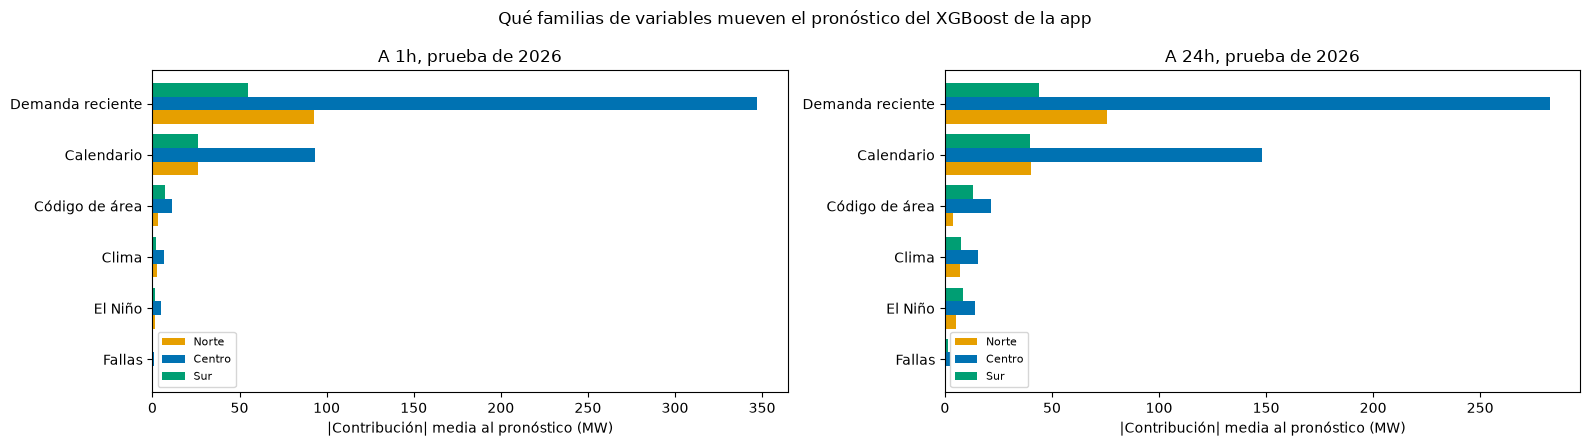

In [5]:
filas = []
for (h, anio), v in shap_mw.items():
    familias_periodo = por_familia(v)
    area = muestras[(h, anio)]["area"].to_numpy()
    for a in AREAS:
        filas.append({"Horizonte": h, "Año": anio, "Área": NOMBRES[a],
                      **familias_periodo[area == a].abs().mean().to_dict()})
familias = pd.DataFrame(filas).set_index(["Horizonte", "Año", "Área"])[list(FAMILIAS)]
display(familias.style.format("{:.1f}").set_caption("Importancia SHAP por familia: |contribución| media al pronóstico (MW)"))

fig, ejes = plt.subplots(1, 2, figsize=(16, 4.5))
for eje, h in zip(ejes, HORIZONTES):
    familias.loc[(h, "2026")].T.iloc[::-1].plot.barh(ax=eje, color=[COLORES[a] for a in AREAS], width=0.8)
    eje.set_title(f"A {h}, prueba de 2026")
    eje.set_xlabel("|Contribución| media al pronóstico (MW)")
    eje.legend(title="", fontsize=8)
plt.suptitle("Qué familias de variables mueven el pronóstico del XGBoost de la app")
plt.tight_layout()
plt.show()

**Lectura del gráfico.**

- **La demanda reciente manda.** En 2026, a 1 h, mueve el pronóstico 347 MW en promedio en el Centro, 93 en el Norte y 55 en el Sur; el calendario es segundo (93, 26 y 27 MW). El modelo pronostica sobre todo a partir de lo que acaba de pasar, y por eso el dato del IEOD de cada media hora es su insumo crítico.
- **A 24 h el calendario gana peso:** 148 MW en el Centro (93 a 1 h), y en el Sur casi iguala a la demanda reciente (39.8 frente a 44.1 MW). Para el programa del día siguiente, saber qué día y qué hora es mañana pesa tanto como lo reciente.
- **Las exógenas mueven poco, pero más en 2026 que en 2025.** A 24 h en el Centro, el clima pasa de 10.5 a 15.7 MW y El Niño de 9.6 a 13.9 MW: con valores que el modelo nunca vio, los usa más. Es justo donde el notebook 03 midió que el clima empeora el pronóstico a 24 h. Las fallas no pasan de 2.4 MW en ningún caso.


## Las variables, una por una

El valor absoluto medio de la contribución de cada variable en 2026, por área. Para leer los nombres: `Area_t` es la
demanda del área en t dividida por su media de 24 h; `Area_media_1h`, la media de la última hora; `Area_semana_pasada`,
la demanda de hace una semana a la hora que se pronostica; `Area_m24_vs_m7d`, la media de 24 h sobre la de 7 días (si
el último día vino alto o bajo); `MinuteOfDay` y `Hour`, la hora de t; `Obj_*`, la hora de t+H; `Week_Sin` y
`DiaSemanaObjetivo`, el día de la semana; `FeriadoObjetivo`, si t+H cae en feriado.


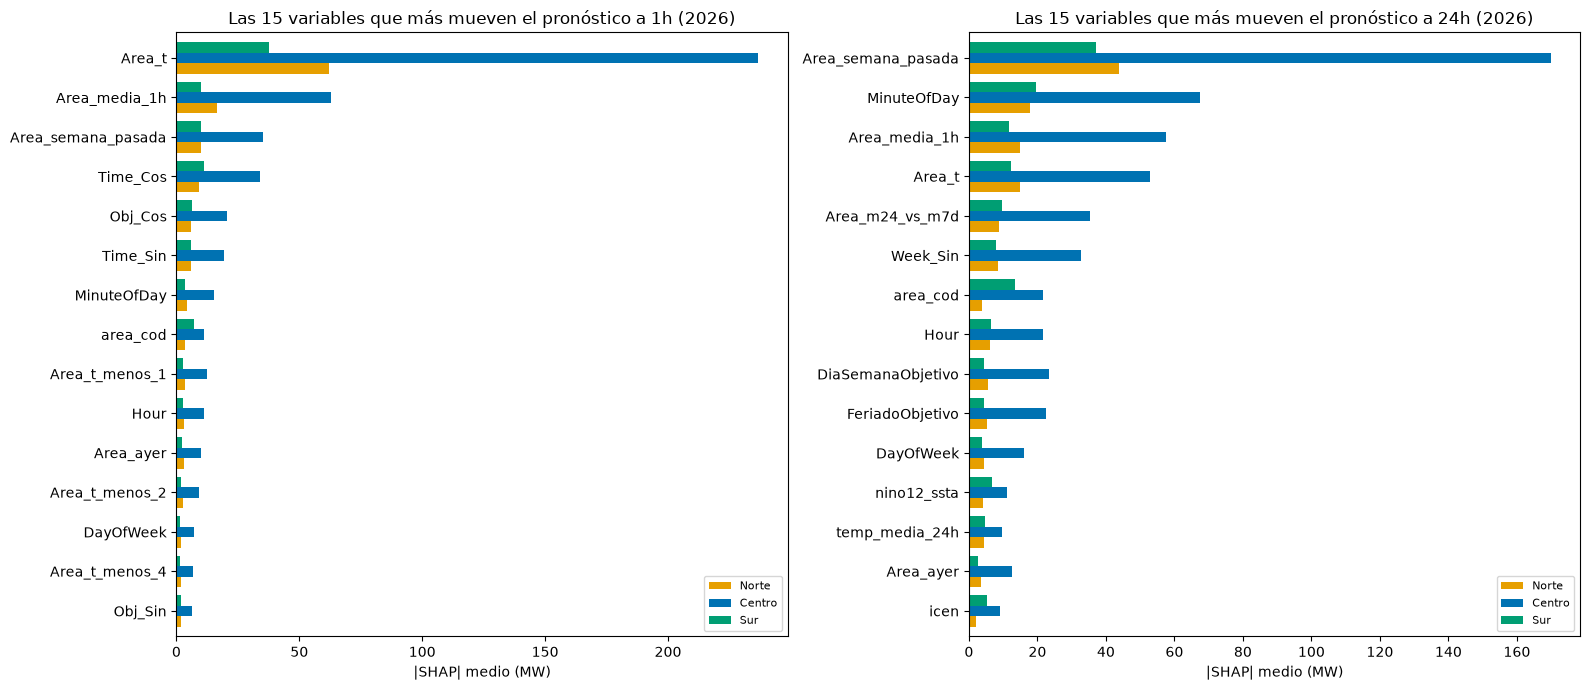

In [6]:
por_variable = {}
for (h, anio), v in shap_mw.items():
    area = muestras[(h, anio)]["area"].to_numpy()
    por_variable[(h, anio)] = pd.DataFrame({NOMBRES[a]: v[area == a].abs().mean() for a in AREAS})


def orden(tabla):
    return tabla.loc[tabla.mean(axis=1).sort_values(ascending=False).index]


fig, ejes = plt.subplots(1, 2, figsize=(16, 7))
for eje, h in zip(ejes, HORIZONTES):
    orden(por_variable[(h, "2026")]).head(15).iloc[::-1].plot.barh(ax=eje, color=[COLORES[a] for a in AREAS], width=0.8)
    eje.set_title(f"Las 15 variables que más mueven el pronóstico a {h} (2026)")
    eje.set_xlabel("|SHAP| medio (MW)")
    eje.legend(fontsize=8)
plt.tight_layout()
plt.show()
display(pd.concat({h: orden(por_variable[(h, "2026")]).head(8) for h in HORIZONTES}).style.format("{:.1f}")
        .set_caption("Las ocho primeras de cada horizonte en 2026 (|SHAP| medio, MW)"))
exogenas = ["temp", "temp_media_24h", "temp_anomalia", "temp_objetivo", "icen", "nino12_ssta", "fallas_en_curso"]
display(pd.concat({anio: por_variable[("24h", anio)].loc[exogenas] for anio in ANIOS.values()}, axis=1)
        .style.format("{:.1f}").set_caption("Las exógenas a 24 h: |SHAP| medio (MW) en 2025 y en 2026"))

**Lectura del gráfico.**

- **A 1 h, una sola variable hace casi todo:** `Area_t` mueve el pronóstico 236.8 MW en el Centro (62.2 en el Norte y 37.6 en el Sur), casi cuatro veces la segunda, la media de la última hora (63.0 MW). El pronóstico a una hora es, en el fondo, «la demanda de ahora, corregida por la hora del día».
- **A 24 h manda la semana pasada:** `Area_semana_pasada` mueve 169.9 MW en el Centro, y después viene la hora del día (`MinuteOfDay`, 67.4 MW). El programa del día siguiente se arma con lo que pasó hace una semana a esa misma hora, que es lo que hace un programador con experiencia.
- **Las exógenas que más crecen en 2026 son las de El Niño y la anomalía de temperatura:** a 24 h en el Centro, `nino12_ssta` pasa de 4.8 a 11.0 MW y `temp_anomalia` de 3.0 a 7.7 MW. Para el operador es una señal de alerta: el modelo se apoya más en variables que están fuera del rango con que se entrenó.


# 4. Beeswarm: hacia dónde empuja cada variable

Cada punto es un periodo de la muestra de 2026 (las tres áreas). La posición horizontal es cuánto movió el pronóstico
esa variable (a la derecha, hacia arriba; a la izquierda, hacia abajo) y el color, el valor de la variable (oscuro,
bajo; claro, alto; escala *cividis*, legible con daltonismo).


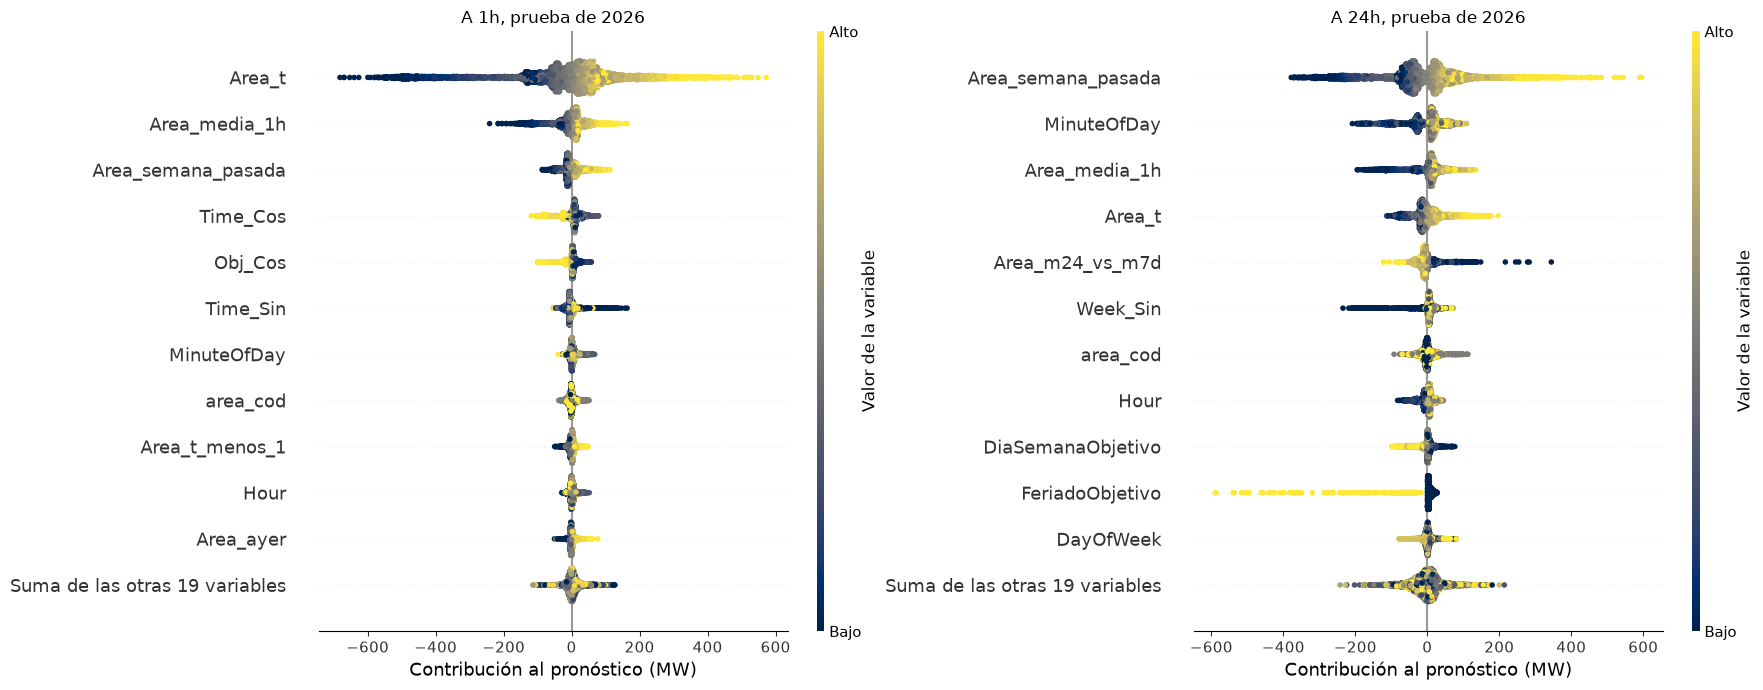

In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(18, 7))
for eje, h in zip(ejes, HORIZONTES):
    v, m = shap_mw[(h, "2026")], muestras[(h, "2026")]
    explicacion = shap.Explanation(values=v.to_numpy(), base_values=m["base_mw"].to_numpy(),
                                   data=m[list(v.columns)].to_numpy(dtype=float), feature_names=list(v.columns))
    shap.plots.beeswarm(explicacion, max_display=12, color=plt.get_cmap("cividis"), ax=eje, show=False,
                        plot_size=None, color_bar_label="Valor de la variable")
    eje.set_title(f"A {h}, prueba de 2026")
    eje.set_xlabel("Contribución al pronóstico (MW)")
    eje.set_yticklabels([e.get_text().replace("Sum of", "Suma de las otras").replace("other features", "variables")
                         for e in eje.get_yticklabels()])
for eje in fig.axes:  # la barra de color de shap viene en inglés
    if eje.get_yticklabels() and {e.get_text() for e in eje.get_yticklabels()} == {"Low", "High"}:
        eje.set_yticklabels(["Bajo", "Alto"])
plt.tight_layout()
plt.show()

**Lectura del gráfico.**

- **`Area_t` empuja en las dos direcciones, de unos −700 a +570 MW:** si la demanda de ahora está alta frente a su media de 24 h (amarillo), el pronóstico sube; si está baja (azul), baja. Es la variable que lleva el pronóstico a 1 h hacia donde va la demanda.
- **El feriado es la señal más fuerte de un solo periodo a 24 h:** cuando `FeriadoObjetivo` vale 1, resta hasta unos 600 MW; cuando vale 0, casi nada. En el promedio queda décima porque hay pocos feriados, pero en esos días decide el pronóstico, y es donde aparece el peor error de 2026 (§7).
- **`Area_m24_vs_m7d` corrige el punto de partida:** cuando el último día vino más bajo que la semana (azul, por ejemplo después de un domingo o un feriado), suma hasta unos 340 MW. Es el mecanismo con que el modelo evita arrastrar un día atípico al siguiente; `Week_Sin` muy bajo (se emite un sábado, así que se pronostica un domingo) resta hasta unos 230 MW.


# 5. Dependencia: las tres variables principales

Cómo cambia la contribución de una variable con su valor, por área: `Area_t` a 1 h (la primera a ese horizonte),
`Area_semana_pasada` y la hora del día a 24 h (las dos primeras a ese horizonte). La pendiente dice cuántos MW
agrega el modelo por cada 0.01 que sube la razón.


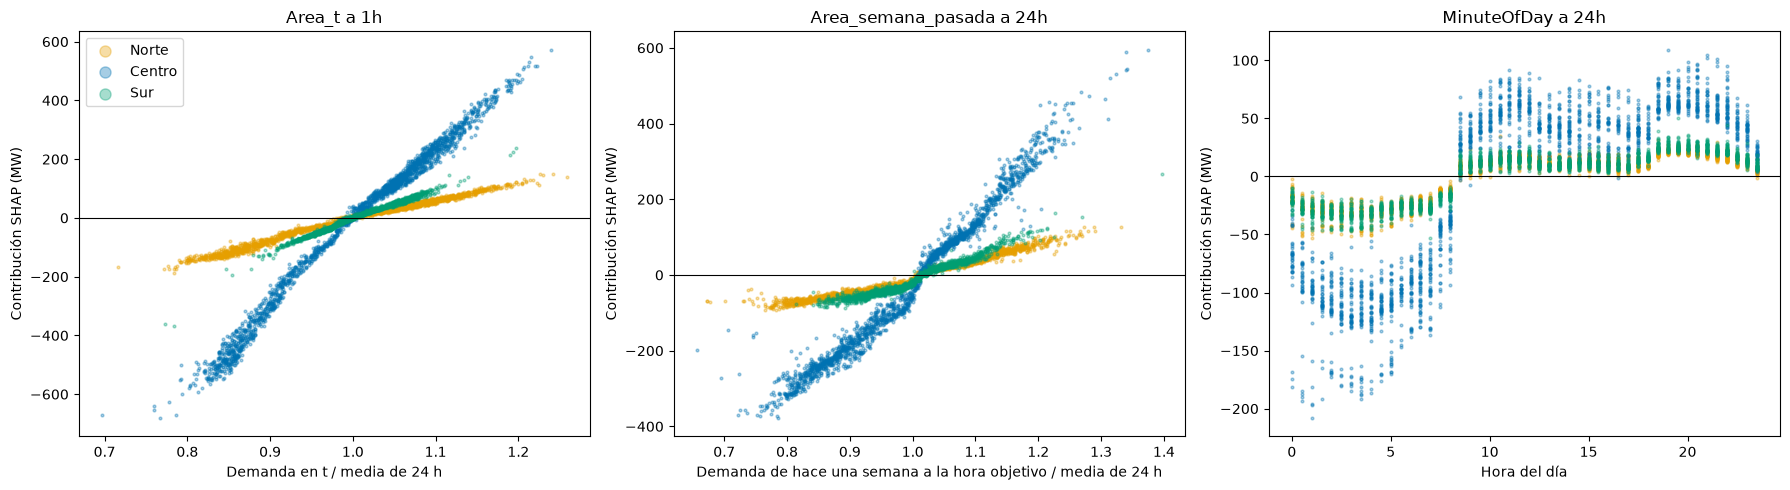

,Centro,Norte,Sur
Area_semana_pasada a 24h,15.9,4.0,6.0
Area_t a 1h,27.1,6.9,10.8


area,Centro,Norte,Sur
MinuteOfDay,,,
4,-115,-32,-31
8,-11,-1,-6
12,+49,+14,+13
16,+41,+11,+10
20,+69,+21,+26


In [8]:
PANELES = [("1h", "Area_t", "Demanda en t / media de 24 h"),
           ("24h", "Area_semana_pasada", "Demanda de hace una semana a la hora objetivo / media de 24 h"),
           ("24h", "MinuteOfDay", "Hora del día")]
fig, ejes = plt.subplots(1, 3, figsize=(18, 5))
pendientes = {}
for eje, (h, var, etiqueta_x) in zip(ejes, PANELES):
    v, m = shap_mw[(h, "2026")], muestras[(h, "2026")]
    x = m[var] / 60 if var == "MinuteOfDay" else m[var]
    for a in AREAS:
        sel = (m["area"] == a).to_numpy()
        eje.scatter(x[sel], v.loc[sel, var], s=4, alpha=0.35, color=COLORES[a], label=NOMBRES[a])
        if var != "MinuteOfDay":
            pendientes[(f"{var} a {h}", NOMBRES[a])] = np.polyfit(x[sel], v.loc[sel, var], 1)[0] / 100
    eje.axhline(0, color="black", lw=0.8)
    eje.set(title=f"{var} a {h}", xlabel=etiqueta_x, ylabel="Contribución SHAP (MW)")
ejes[0].legend(markerscale=4)
plt.tight_layout()
plt.show()
display(pd.Series(pendientes).unstack().round(1).style.format("{:.1f}")
        .set_caption("Pendiente: MW que suma el modelo por cada 0.01 más de la razón (ajuste lineal, 2026)"))
hora = muestras[("24h", "2026")]["MinuteOfDay"] // 60
display(shap_mw[("24h", "2026")]["MinuteOfDay"].groupby([muestras[("24h", "2026")]["area"].map(NOMBRES), hora]).mean()
        .unstack(0).loc[[4, 8, 12, 16, 20]].round(0).style.format("{:+.0f}")
        .set_caption("Contribución media de la hora del día a 24 h (MW), a algunas horas"))

**Lectura del gráfico.**

- **`Area_t` a 1 h es casi una recta:** por cada 0.01 que la demanda de ahora supera su media de 24 h, el modelo suma 27.1 MW en el Centro, 6.9 en el Norte y 10.8 en el Sur, en proporción al tamaño de cada área. En el Centro es cerca de 60 % del 1 % de su demanda media (4,376 MW en 2026); el resto se lo reparten variables casi iguales, como la media de la última hora.
- **`Area_semana_pasada` a 24 h tiene forma de S:** casi plana cuando la semana pasada a esa hora estuvo por debajo de la media (las noches) y empinada cuando estuvo por encima (las horas de punta), con 15.9 MW por cada 0.01 en el Centro. El modelo confía más en la semana pasada justo en las horas que más importan.
- **La hora del día a 24 h funciona como un interruptor:** en el Centro resta 115 MW a las 4 h, casi nada a las 8 h y suma 49 MW a las 12 h y 69 MW a las 20 h. El salto está alrededor de las 8:30, la rampa de la mañana; para el operador, es la hora en que el pronóstico pasa de «noche» a «día».


# 6. Frente a la importancia por permutación del notebook 02

El notebook 02 (§11) publicó la importancia por permutación del Random Forest por área, M3 a 1 h, en la validación de
2025: cuánto sube el MAE al desordenar cada variable, sumado por grupo. Para separar lo que cambia por el **método**
de lo que cambia por el **modelo**, se calcula también la permutación del XGBoost de la app en la misma muestra de
2026 que SHAP (tres repeticiones), y SHAP se suma por variable y por grupo de la misma forma.


In [9]:
# Tabla «Por grupo de variables» del notebook 02 (§11), tal como se publicó
PERMUTACION_02 = pd.DataFrame({"Norte": [49.46, 0.18, 0.02, 0.00], "Centro": [247.97, 1.10, 0.04, -0.01],
                               "Sur": [43.37, 0.23, 0.02, 0.00]},
                              index=["M0 (demanda y calendario)", "Clima", "El Niño", "Fallas"])


def grupos_02(por_var):
    # Suma por grupo, como el notebook 02: demanda reciente + calendario + área = M0
    grupo = por_var.index.map(lambda c: "M0 (demanda y calendario)" if familia_de(c) in FAMILIAS_M0 else familia_de(c))
    return por_var.groupby(grupo).sum().reindex(PERMUTACION_02.index)


inicio, permutacion = time.time(), {}
for h in HORIZONTES:
    m = muestras[(h, "2026")]
    permutacion[h] = pd.DataFrame({
        NOMBRES[a]: pd.Series(permutation_importance(modelos[h], m.loc[m["area"] == a, COLS[h]], m.loc[m["area"] == a, "real"],
                                                     scoring="neg_mean_absolute_error", n_repeats=3,
                                                     random_state=SEMILLA).importances_mean, index=COLS[h])
        for a in AREAS}).drop(index="media_24h")
print(f"Permutación en {(time.time() - inicio) / 60:.1f} min")
comparacion = pd.concat({
    "Permutación · RF por área · 2025 · 1 h (notebook 02)": PERMUTACION_02,
    "Permutación · XGBoost de la app · 2026 · 1 h": grupos_02(permutacion["1h"]),
    "SHAP · XGBoost de la app · 2026 · 1 h": grupos_02(por_variable[("1h", "2026")]),
    "Permutación · XGBoost de la app · 2026 · 24 h": grupos_02(permutacion["24h"]),
    "SHAP · XGBoost de la app · 2026 · 24 h": grupos_02(por_variable[("24h", "2026")]),
})
display(comparacion.style.format("{:.2f}")
        .set_caption("Por grupo (MW). Permutación: cuánto sube el MAE al desordenar. SHAP: cuánto mueve el pronóstico"))
puestos = pd.DataFrame({
    "Permutación XGBoost 1 h": permutacion["1h"].mean(axis=1).rank(ascending=False),
    "SHAP XGBoost 1 h": por_variable[("1h", "2026")].mean(axis=1).rank(ascending=False),
    "Permutación XGBoost 24 h": permutacion["24h"].mean(axis=1).rank(ascending=False),
    "SHAP XGBoost 24 h": por_variable[("24h", "2026")].mean(axis=1).rank(ascending=False),
}).astype(int).sort_values("SHAP XGBoost 1 h")
display(puestos.head(12).style.set_caption("Puesto de cada variable (1 = la más importante, media de las tres áreas)"))
display(pd.concat({"Permutación 1 h": permutacion["1h"].loc[["Area_t", "Area_media_1h", "Area_t_menos_1"]],
                   "SHAP 1 h": por_variable[("1h", "2026")].loc[["Area_t", "Area_media_1h", "Area_t_menos_1"]]}, axis=1)
        .style.format("{:.1f}").set_caption("Tres variables casi iguales: la demanda en t, la media de la última hora y t−1 (MW)"))

Permutación en 0.4 min


,Permutación XGBoost 1 h,SHAP XGBoost 1 h,Permutación XGBoost 24 h,SHAP XGBoost 24 h
Area_t,1,1,5,4
Area_media_1h,2,2,6,3
Area_semana_pasada,11,3,2,1
Time_Cos,3,4,13,16
Obj_Cos,6,5,30,25
Time_Sin,5,6,17,17
MinuteOfDay,4,7,1,2
area_cod,29,8,27,7
Area_t_menos_1,9,9,19,28
Hour,8,10,8,8


**Por qué no dicen lo mismo, y qué se mantiene.**

1. **Responden preguntas distintas.** La permutación mide cuánto **empeora el error** si se pierde una variable; SHAP,
   cuánto **mueve el pronóstico**. Por eso las cifras de SHAP son mayores (514 frente a 394 MW para el grupo M0 en el
   Centro a 1 h) y no se suman ni se restan con las de la permutación.
2. **Lo esencial coincide.** Con los dos métodos y los dos modelos, la demanda reciente y el calendario lo explican casi
   todo. A 1 h, `Area_t` y `Area_media_1h` son las dos primeras para la permutación y para SHAP; a 24 h, la semana
   pasada y la hora del día están entre las dos primeras en ambos. La conclusión del notebook 02 sobrevive al cambio de
   método y de modelo.
3. **Las variables casi iguales se reparten el mérito.** `Area_t`, `Area_media_1h` y `Area_t_menos_1` traen casi la
   misma información: al desordenar una, las otras la cubren y la permutación le da poco (8.7 MW a `Area_t_menos_1` en
   el Centro); SHAP reparte el crédito entre ellas (12.3 MW). Lo mismo pasa con `Area_semana_pasada` a 1 h: tercera con
   SHAP y undécima con la permutación, porque `Area_t` la reemplaza.
4. **`area_cod` es cero en la permutación por construcción.** Se calcula área por área, y dentro de un área el código no
   cambia: desordenarlo no hace nada (puesto 29). SHAP sí le asigna lo que cada área se aparta del patrón común de las
   tres (de 3 a 11 MW a 1 h).
5. **Las exógenas: el modelo las usa, pero no las necesita.** SHAP les da entre 2 y 12 MW a 1 h, y la permutación del
   XGBoost entre 0.3 y 2.2 MW (en el Random Forest del notebook 02, de 0.02 a 1.1). En el Sur a 24 h, desordenar El Niño
   sube el error 12.5 MW: el modelo se apoya en esas variables. Pero la ablación del notebook 03, que reentrena sin
   ellas, mostró que sumarlas no mejora (y que El Niño empeora el Sur a 24 h en 0.83 MW): sin ellas, el modelo compensa
   con otras. Depender de una variable no es lo mismo que necesitarla.
6. **Cambian el modelo y el año.** El notebook 02 midió el Random Forest por área en 2025; aquí es el XGBoost global en
   2026, con El Niño y temperaturas fuera de lo visto. Por eso las exógenas pesan algo más aquí que allá.


# 7. Tres casos locales

Explicar un pronóstico concreto es lo que necesita el operador cuando un número le llama la atención. Se eligen
tres casos de la prueba de 2026, **a 24 h** (el programa del día siguiente, donde el calendario y las exógenas pesan
más), con una regla escrita antes de mirar sus explicaciones:

1. **Un pico de demanda bien pronosticado:** entre los 20 periodos de más demanda del Centro en 2026, el de menor
   error.
2. **El peor error de 2026:** el periodo con mayor error absoluto en las tres áreas.
3. **Un día de El Niño:** en el Norte, en agosto de 2026 (el ICEN de 3.98, el más alto del episodio), el periodo en
   que las variables de El Niño más movieron el pronóstico.

**Antes, un control de datos.** En el anexo del COES hay periodos sueltos en que la demanda de un área salta más de 10 %
en media hora y vuelve en la siguiente, mientras el SEIN no se mueve: es demanda que el anexo asigna a otra área
durante media hora, no consumo. Ningún modelo puede anticiparla y explicarla con SHAP no tiene sentido, así que se
marcan y quedan fuera de la elección.


In [10]:
def saltos_aislados(area, umbral=0.10):
    # Periodos en que la demanda del área sube o baja más que `umbral` en media hora y vuelve en la siguiente
    s = corrida.demanda.set_index("DateTime")[area]
    antes, despues = s / s.shift(1) - 1, s.shift(-1) / s - 1
    marca = (antes.abs() > umbral) & (despues.abs() > umbral) & (np.sign(antes) != np.sign(despues))
    return set(s.index[marca & (s.index >= "2026-01-01")])


SALTOS = {a: saltos_aislados(a) for a in AREAS}
print("Saltos aislados en 2026:", {NOMBRES[a]: sorted(str(x) for x in s) for a, s in SALTOS.items()})
display(corrida.demanda.set_index("DateTime").loc["2026-08-04 11:00":"2026-08-04 13:00"]
        .style.format("{:,.1f}").set_caption("El 4 de agosto de 2026 a las 12:00: el Norte cae y el Centro sube lo mismo; el SEIN, no"))

prueba = {}
for h, pasos in HORIZONTES.items():
    t = tramo(datos[h], "prueba").copy()
    t["pred"] = modelos[h].predict(t[COLS[h]])
    t["error"] = t["real"] - t["pred"]
    t["objetivo"] = t["DateTime"] + pasos * PASO
    t["salto"] = [o in SALTOS[a] for o, a in zip(t["objetivo"], t["area"])]
    prueba[h] = t
peores = {h: t.loc[t["error"].abs().idxmax(), ["area", "objetivo", "real", "pred", "error", "salto"]] for h, t in prueba.items()}
display(pd.DataFrame(peores).T.style.set_caption("El peor error de 2026 en cada horizonte, sin excluir nada"))

p24 = prueba["24h"]
limpio = p24[~p24["salto"]]
picos_centro = limpio[limpio["area"] == "CENTRO"].nlargest(20, "real")
CASO_PICO = picos_centro["error"].abs().idxmin()
CASO_PEOR = limpio["error"].abs().idxmax()
norte_agosto = limpio[(limpio["area"] == "NORTE") & (limpio["objetivo"].dt.month == 8)]
nino_agosto = por_familia(explicar("24h", norte_agosto)[0])["El Niño"]
CASO_NINO = nino_agosto.abs().idxmax()
casos = p24.loc[[CASO_PICO, CASO_PEOR, CASO_NINO]].assign(
    caso=["1. Pico bien pronosticado", "2. Peor error de 2026", "3. Día de El Niño"],
    error_pct=lambda t: 100 * t["error"] / t["real"]).set_index("caso")
display(casos[["area", "objetivo", "real", "pred", "error", "error_pct", "FeriadoObjetivo", "DiaSemanaObjetivo", "icen",
               "nino12_ssta", "temp_objetivo"]].style.format(precision=2).set_caption("Los tres casos (a 24 h)"))
print(f"MAE a 24 h en 2026 para comparar: {p24.groupby('area')['error'].apply(lambda e: e.abs().mean()).round(1).to_dict()}")
print(f"El Niño en el Norte en agosto: contribución media {nino_agosto.mean():+.1f} MW, "
      f"entre {nino_agosto.min():+.1f} y {nino_agosto.max():+.1f} MW")

Saltos aislados en 2026: {'Norte': ['2026-04-28 05:30:00', '2026-08-04 12:00:00', '2026-08-19 12:00:00'], 'Centro': ['2026-08-04 12:00:00'], 'Sur': ['2026-01-12 02:30:00', '2026-01-28 14:00:00', '2026-02-01 17:00:00']}


,SEIN,NORTE,CENTRO,SUR
DateTime,,,,
2026-08-04 11:00:00,"7,806.0","1,231.4","4,849.7","1,724.9"
2026-08-04 11:30:00,"7,788.4","1,251.5","4,878.4","1,658.5"
2026-08-04 12:00:00,"7,857.5",564.4,"5,579.7","1,713.3"
2026-08-04 12:30:00,"7,746.2","1,233.7","4,820.6","1,691.9"
2026-08-04 13:00:00,"7,643.5","1,226.3","4,765.2","1,652.0"


,area,objetivo,real,pred,error,salto
1h,CENTRO,2026-08-04 12:00:00,5579.739500,4834.411478,745.328022,True
24h,CENTRO,2026-06-29 13:00:00,4366.645600,3590.973213,775.672387,False


,area,objetivo,real,pred,error,error_pct,FeriadoObjetivo,DiaSemanaObjetivo,icen,nino12_ssta,temp_objetivo
caso,,,,,,,,,,,
1. Pico bien pronosticado,CENTRO,2026-02-24 15:00:00,5379.79,5367.10,12.69,0.24,0,1,-0.51,0.80,28.73
2. Peor error de 2026,CENTRO,2026-06-29 13:00:00,4366.65,3590.97,775.67,17.76,1,0,1.34,3.10,25.64
3. Día de El Niño,NORTE,2026-08-02 00:30:00,991.32,1004.23,-12.91,-1.30,0,6,1.98,3.60,24.03


MAE a 24 h en 2026 para comparar: {'CENTRO': 85.3, 'NORTE': 32.8, 'SUR': 51.0}
El Niño en el Norte en agosto: contribución media -6.7 MW, entre -19.7 y +10.2 MW


In [11]:
def cascada(indice, titulo, h="24h", top=9):
    # Waterfall de un pronóstico en MW: del punto de partida (base × media de 24 h) al pronóstico, variable por variable
    filas = prueba[h].loc[[indice]]
    v, base, pred = explicar(h, filas)
    tabla = contribuciones(v.iloc[0], filas.iloc[0], top=top)
    real = float(filas["real"].iloc[0])
    fig, eje = plt.subplots(figsize=(12, 5.5))
    posicion, etiquetas = base[0], []
    for i, fila in enumerate(tabla.itertuples()):
        c = fila.contribucion_mw
        eje.barh(i, c, left=posicion, color=SUBE if c > 0 else BAJA, height=0.6)
        eje.annotate(f"{c:+.0f}", (posicion + c, i), xytext=(4 if c > 0 else -4, 0), textcoords="offset points",
                     va="center", ha="left" if c > 0 else "right", fontsize=9)
        posicion += c
        etiquetas.append(fila.variable if pd.isna(fila.valor) else f"{fila.variable} = {fila.valor:.3g}")
    eje.set_yticks(range(len(tabla)), etiquetas)
    eje.invert_yaxis()
    extremos = np.concatenate([[base[0], pred[0], real], base[0] + tabla["contribucion_mw"].cumsum().to_numpy()])
    margen = 0.12 * (extremos.max() - extremos.min())
    eje.set_xlim(extremos.min() - margen, extremos.max() + margen)
    eje.axvline(base[0], color="grey", ls="--", lw=1, label=f"Punto de partida (base × media de 24 h): {base[0]:,.0f} MW")
    eje.axvline(pred[0], color="black", lw=1.3, label=f"Pronóstico: {pred[0]:,.0f} MW")
    eje.axvline(real, color="black", ls=":", lw=2, label=f"Real: {real:,.0f} MW")
    eje.set_xlabel("MW")
    eje.set_title(titulo)
    eje.legend(loc="best", fontsize=8)
    plt.tight_layout()
    plt.show()
    return tabla.assign(contribucion_mw=tabla["contribucion_mw"].round(1))


def titulo(indice, que):
    f = p24.loc[indice]
    return f"{que}: {NOMBRES[f['area']]}, {f['objetivo']:%d/%m/%Y %H:%M}, pronosticado 24 h antes"

## Caso 1: un pico de demanda bien pronosticado


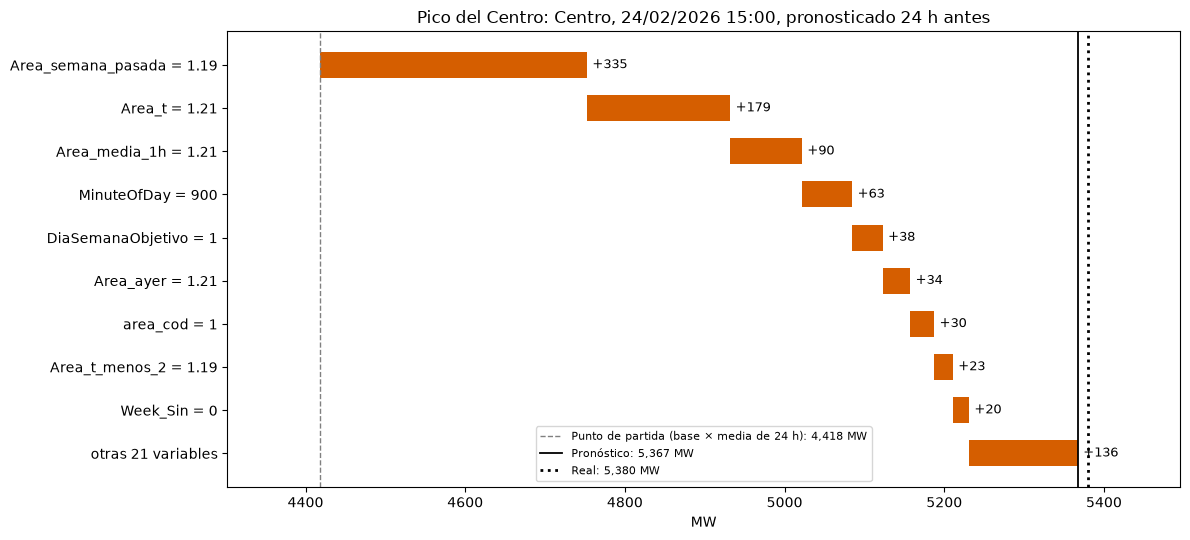

,variable,valor,contribucion_mw
0,Area_semana_pasada,1.190933,334.6
1,Area_t,1.206442,179.4
2,Area_media_1h,1.207786,89.8
3,MinuteOfDay,900.000000,63.0
4,DiaSemanaObjetivo,1.000000,38.2
5,Area_ayer,1.206442,34.4
6,area_cod,1.000000,30.0
7,Area_t_menos_2,1.190415,23.4
8,Week_Sin,0.000000,20.2
9,otras 21 variables,NaN,136.3


In [12]:
display(cascada(CASO_PICO, titulo(CASO_PICO, "Pico del Centro")))

**Lectura del gráfico.**

- **Un pico de verano pronosticado con 13 MW de error.** El martes 24 de febrero de 2026 a las 15:00 el Centro demandó 5,380 MW, uno de sus 20 periodos más altos del año, y el modelo había dicho 5,367 MW un día antes: 0.24 % de error, frente a 85.3 MW de error medio del Centro a 24 h.
- **Lo construye con el ciclo diario, no con el clima.** Desde el nivel del último día (4,418 MW), la semana pasada a esa hora (19 % sobre la media de las últimas 24 h) suma 335 MW, el lunes a esa hora (21 % sobre la media) 179 MW, la media de esa última hora 90 MW, las 15:00 63 MW y el martes 38 MW. Ninguna variable de clima está entre las nueve primeras, aun con 28.7 °C de pronóstico en Lima.
- **Para el operador:** el pico se anticipa porque el lunes y el martes anteriores ya habían sido altos a esa hora. El modelo acierta los picos que se vienen gestando; los que llegan de golpe, sin aviso en la demanda reciente, son los que se le escapan (notebook 02).


## Caso 2: el peor error de 2026


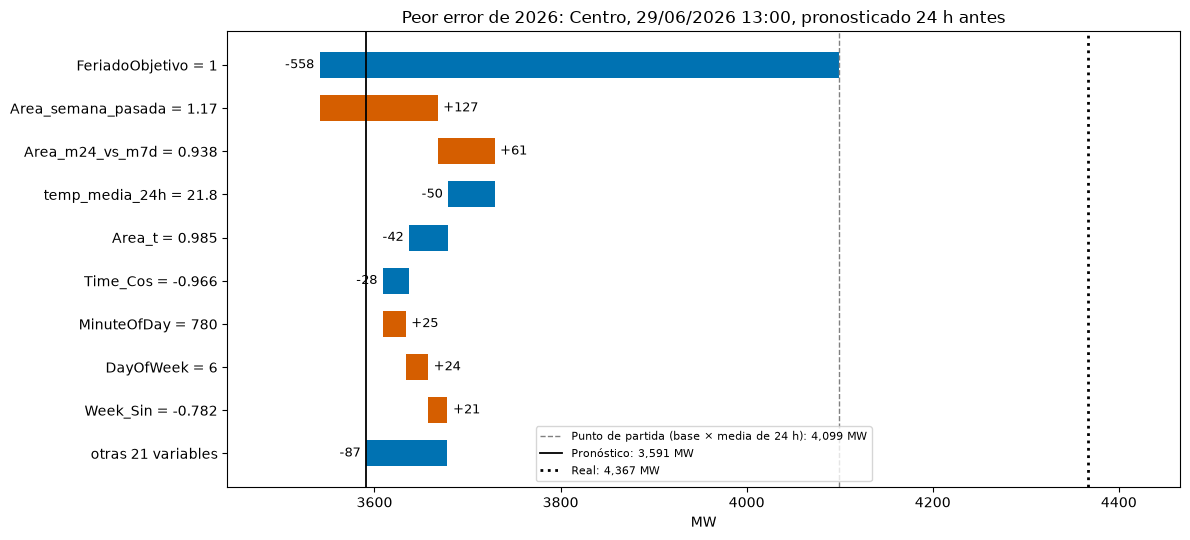

,variable,valor,contribucion_mw
0,FeriadoObjetivo,1.000000,-558.5
1,Area_semana_pasada,1.166379,126.8
2,Area_m24_vs_m7d,0.938214,61.1
3,temp_media_24h,21.775000,-49.8
4,Area_t,0.984625,-42.0
5,Time_Cos,-0.965926,-28.3
6,MinuteOfDay,780.000000,24.6
7,DayOfWeek,6.000000,24.1
8,Week_Sin,-0.781831,20.8
9,otras 21 variables,NaN,-87.5


,lunes 29/06/2026
Real en el periodo (MW),4366.6
Pronóstico (MW),3591.0
"Misma hora, el día anterior (MW)",4027.8
"Misma hora, una semana antes (MW)",4771.3
"Error medio del día, a 24 h (MW)",387.0


Feriados entre semana en el entrenamiento (2016-2024): 87, de los cuales 13 cayeron en lunes


In [13]:
display(cascada(CASO_PEOR, titulo(CASO_PEOR, "Peor error de 2026")))
f = p24.loc[CASO_PEOR]
dia = f["objetivo"].normalize()
serie_area = corrida.demanda.set_index("DateTime")[f["area"]]
DIAS = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
contexto = pd.Series({
    "Real en el periodo (MW)": f["real"],
    "Pronóstico (MW)": f["pred"],
    "Misma hora, el día anterior (MW)": serie_area.get(f["objetivo"] - pd.Timedelta(days=1)),
    "Misma hora, una semana antes (MW)": serie_area.get(f["objetivo"] - pd.Timedelta(days=7)),
    "Error medio del día, a 24 h (MW)": p24[(p24["area"] == f["area"]) & (p24["objetivo"].dt.normalize() == dia)]["error"].mean(),
})
display(contexto.round(1).to_frame(f"{DIAS[dia.day_of_week]} {dia:%d/%m/%Y}"))
feriados = pd.DatetimeIndex(pd.to_datetime(corrida.feriados))
entre_semana = feriados[(feriados.year <= 2024) & (feriados.day_of_week < 5)]
print(f"Feriados entre semana en el entrenamiento (2016-2024): {len(entre_semana)}, "
      f"de los cuales {(entre_semana.day_of_week == 0).sum()} cayeron en lunes")

**Lectura del gráfico.**

- **El peor error de 2026 es un feriado: 776 MW (17.8 %).** El lunes 29 de junio (San Pedro y San Pablo) a las 13:00 el Centro demandó 4,367 MW y el modelo había dicho 3,591, menos que el domingo anterior a esa hora (4,028 MW). En todo el día, el error medio fue de 387 MW.
- **La explicación: restó el feriado sobre un punto de partida que ya era de fin de semana.** `FeriadoObjetivo` le quita 558 MW al pronóstico. Pero el punto de partida (4,099 MW) sale de la media de las últimas 24 h, que era la de un fin de semana (de sábado a domingo). El modelo aprendió el efecto del feriado sobre todo con feriados que siguen a un día hábil (de los 87 feriados entre semana de 2016 a 2024, solo 13 cayeron en lunes) y lo aplicó entero sobre un día que ya venía bajo. La semana pasada (un lunes normal, 4,771 MW) y el nivel bajo del último día (`Area_m24_vs_m7d`) empujan hacia arriba (+127 y +61 MW), pero no alcanzan.
- **Qué hacer con esto:** los feriados que caen en lunes son el punto ciego del programa del día siguiente. Una variable que diga si el día anterior fue domingo o feriado, o medir el feriado frente a un domingo y no frente a un día hábil, es la mejora más directa que deja este notebook. Mientras tanto, el operador debería revisar a mano el pronóstico de esos días. (A 1 h, el peor error del año es otro: el traspaso del 4 de agosto, que no es consumo.)


## Caso 3: un día de El Niño en el Norte


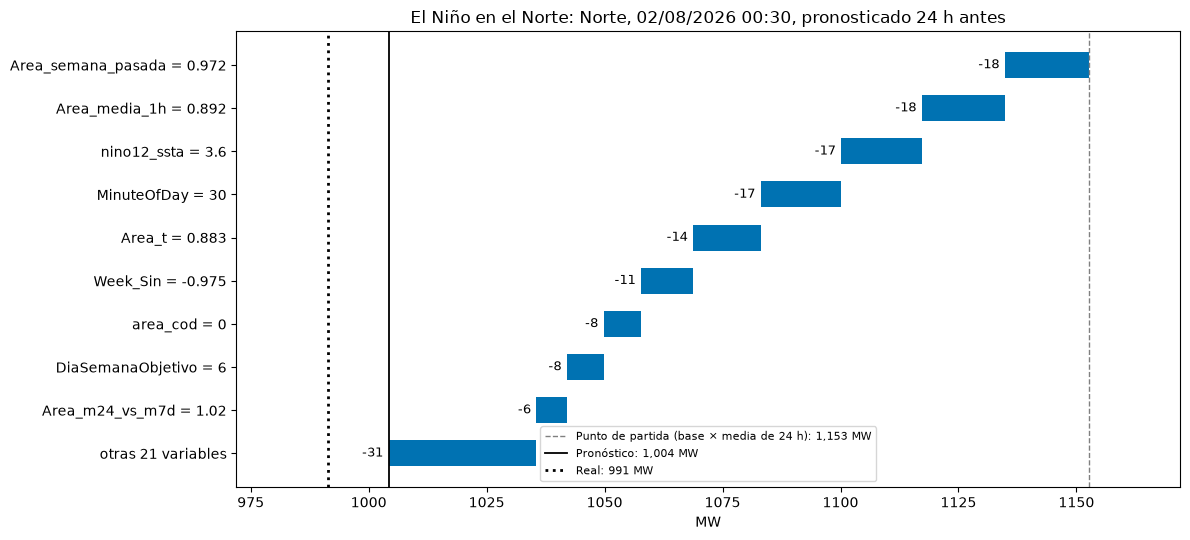

,variable,valor,contribucion_mw
0,Area_semana_pasada,0.972270,-17.8
1,Area_media_1h,0.891741,-17.6
2,nino12_ssta,3.600000,-17.1
3,MinuteOfDay,30.000000,-17.1
4,Area_t,0.882791,-14.3
5,Week_Sin,-0.974928,-11.0
6,area_cod,0.000000,-7.9
7,DiaSemanaObjetivo,6.000000,-7.8
8,Area_m24_vs_m7d,1.019992,-6.5
9,otras 21 variables,NaN,-31.3


In [14]:
display(cascada(CASO_NINO, titulo(CASO_NINO, "El Niño en el Norte")))

**Lectura del gráfico.**

- **En pleno El Niño, El Niño mueve el pronóstico menos de 20 MW.** Es el periodo de agosto de 2026 (el ICEN más alto del episodio, 3.98) en que las variables de El Niño más pesaron: el domingo 2 de agosto a las 00:30, con un Niño 1+2 de +3.6 °C, `nino12_ssta` resta 17 MW de 1,004. En todo agosto, El Niño suma en promedio −6.7 MW (entre −19.7 y +10.2) al pronóstico del Norte.
- **Y empuja hacia abajo.** El modelo aprendió El Niño de los episodios del entrenamiento, y en el de 2017 la demanda del Norte cayó 6 a 7 % (notebook 01). En 2026 la demanda del Norte crece hasta 17 %: si el modelo dependiera de El Niño, pronosticaría al revés.
- **El nivel lo trae la escala, no El Niño:** el punto de partida (1,153 MW, la media de las últimas 24 h) ya contiene el crecimiento de 2026, y el pronóstico acierta (13 MW de error, 1.3 %). Es la razón de fondo de que el objetivo en razón aguante El Niño sin reentrenar, y de que las variables de El Niño no ayuden (notebook 03).


# 8. Privacidad y seguridad del modelo

Para el **Entregable 8** (explicabilidad, herramientas de explicabilidad, privacidad y seguridad del modelo del grupo).

**Datos y privacidad.**

- **No hay datos personales.** El modelo usa la demanda **agregada por área operativa** (Norte, Centro y Sur), en MW
  cada 30 minutos, del IEOD del COES; ni un cliente, ni un medidor, ni un hogar. Las exógenas también son agregadas:
  temperatura de ERA5 por ciudad, índices de El Niño (ICEN del IGP y Niño 1+2 de NOAA) y eventos de la red del COES,
  que nombran empresas y equipos, no personas. No hay riesgo de reidentificación porque no hay a quién identificar.
- **Licencias y uso.** La demanda y los eventos son datos públicos del COES, sin licencia publicada: se citan como
  fuente, se usan con fines académicos y los archivos crudos no se suben al repositorio (`data/` no se versiona). ERA5
  vía Open-Meteo es CC BY 4.0 y el SAIDI de Osinergmin, ODC-By; el detalle está en la tabla de datos del README.
  Los pesos de los modelos fundacionales del notebook 04 tienen licencias distintas (TimesFM 3.0 es no comercial).
- **Trazabilidad.** Cada capa guarda su procedencia con sha256, y el pipeline (`pipeline_sein`) la devuelve con su
  versión: se sabe con qué datos exactos salió cada cifra.

**Riesgos de un modelo de pronóstico en operación**, con lo que mostró este notebook:

1. **Un dato de entrada malo se vuelve un pronóstico malo.** La familia que más mueve el pronóstico es la demanda
   reciente (§3); si el anexo llega tarde o con un error, el pronóstico lo hereda. El 4 de agosto de 2026, media hora
   de demanda asignada al Centro en vez del Norte produjo el peor error a 1 h del año (§7).
2. **Fuera de lo visto, las exógenas mueven más el pronóstico sin mejorarlo.** En 2026 las variables de clima y de
   El Niño pesan más que en 2025 (§3), con valores que el modelo nunca vio, y el notebook 03 midió que a 24 h el clima
   empeora el error. Es un riesgo de deriva, no un fallo puntual.
3. **Subestimar un pico cuesta más que sobrestimarlo:** deja al operador corto de reserva. Los picos extremos del
   Centro quedan por debajo de lo real (notebook 02), y el peor error de 2026 fue un feriado en lunes pronosticado
   776 MW por debajo (§7).
4. **Exceso de confianza en el rango.** En vivo, el rango del 80 % del modelo que se registra cada día quedó corto
   (README): un operador que lo tome al pie de la letra subestima la incertidumbre.
5. **Manipulación y exposición.** La API recibe pedidos por la red (área, origen, horizonte y escenarios como «¿y si
   hace más calor?»): sin límites, alguien podría pedir valores absurdos o cargar el servidor.

**Controles que ya existen** (en el código del repositorio):

- **Validación del anexo** antes de usarlo (`en_vivo.validar_dia` y `validar_empalme`): los 48 periodos del día, sin
  vacíos, positivos, Norte + Centro + Sur = SEIN (±1 MW) y un empalme con el día anterior sin saltos fuera de lo visto.
  Si falla, no se emite nada.
- **Registro inmutable de pronósticos** (`reportes/sein/en_vivo/pronosticos.parquet`): solo crece, cada fila lleva su
  sello de emisión, el sha256 de los datos y la versión del código, y se marca si fue *ex ante*, en vivo o
  reconstruida. Nadie puede «mejorar» un pronóstico después de ver el real.
- **La regla de información** está probada (tests y la verificación del pipeline): ninguna variable usa un dato que
  en t no se había publicado.
- **Publicación atómica de modelos** (`pronosticador_real._publicar`): la app nunca carga una mezcla de dos
  entrenamientos.
- **Entradas acotadas por contrato** (`app/backend/contrato.py`, con pydantic): un escenario solo puede mover la
  temperatura −2, +2 o +4 °C, poner El Niño en neutro o quitar las fallas; el origen tiene un formato fijo y el área y el
  horizonte, valores cerrados. No hay forma de inyectar un valor arbitrario en el modelo.
- **La app dice cuánto acertó:** el error de 2026 mes a mes, la cobertura del rango también en vivo y la comparación
  con la mejor referencia ingenua. La demo va por Tailscale y no por Internet abierta (`docs/producto-final.md`).

**Lo que falta, y este notebook lo sugiere:** la validación del anexo no detecta un traspaso como el del 4 de agosto,
porque la suma de las áreas sí da el SEIN; un control de **saltos aislados por área** (el de la §7) lo marcaría antes de
pronosticar. Y conviene un **monitoreo de deriva** de las exógenas: avisar cuando la temperatura o el ICEN salen del
rango de entrenamiento, que es justo cuando el clima deja de ayudar.


# 9. Guardar

Las tablas de este notebook quedan en `reportes/sein/explicabilidad/` para el paper y la app.


In [15]:
salida = RAIZ / "reportes" / "sein" / "explicabilidad"
salida.mkdir(parents=True, exist_ok=True)
familias.to_csv(salida / "shap_por_familia.csv")
pd.concat({f"{h}_{anio}": t for (h, anio), t in por_variable.items()}).to_csv(salida / "shap_por_variable.csv")
comparacion.to_csv(salida / "shap_frente_a_permutacion.csv")
casos.to_csv(salida / "casos_locales.csv")
print("Tablas en", salida)

Tablas en /home/rody/Code/lab/courses/tetouan-power-forecast/data/reportes/sein/explicabilidad


# Conclusiones

1. **El modelo de la app pronostica con la demanda reciente y el calendario.** En la prueba de 2026, la demanda reciente
   mueve el pronóstico 347 MW en el Centro a 1 h y el calendario 93 MW; el clima, El Niño y las fallas, entre 1 y 7 MW. A
   1 h manda la demanda de ahora (`Area_t`, 236.8 MW en el Centro); a 24 h, la de la semana pasada a la misma hora
   (169.9 MW) y la hora del día (67.4 MW).
2. **SHAP confirma lo esencial de la importancia por permutación del notebook 02**, con otro método y otro modelo: las
   mismas variables arriba. Las diferencias tienen explicación: la permutación mide el daño al error y SHAP el movimiento
   del pronóstico, las variables casi iguales se reparten el mérito, y `area_cod` no se puede permutar dentro de un área.
3. **Las exógenas se usan más fuera de lo visto, sin ayudar.** En 2026 el clima y El Niño pesan alrededor de 50 % más
   que en 2025 a 24 h en el Centro (15.7 y 13.9 MW frente a 10.5 y 9.6). El modelo se apoya en ellas, pero la ablación del
   notebook 03 mostró que no mejoran el error: depender de una variable no es necesitarla.
4. **El peor error de 2026 tiene una causa concreta:** el feriado del lunes 29 de junio (776 MW, 17.8 %), donde el modelo
   restó 558 MW por el feriado sobre un punto de partida que ya era de domingo. Los feriados en lunes son su punto ciego, y
   la mejora sugerida es una variable que diga si el día anterior fue domingo o feriado.
5. **Los picos que se gestan se aciertan:** el del 24 de febrero en el Centro (5,380 MW) se pronosticó con 13 MW de error,
   armado con la semana pasada y el día anterior a esa hora, sin el clima.
6. **El Niño no sostiene el pronóstico del Norte; la escala sí.** En agosto de 2026, El Niño mueve el pronóstico menos de
   20 MW y hacia abajo (aprendido de 2017); el crecimiento lo trae la media de 24 h.
7. **Privacidad y seguridad:** el modelo no usa datos personales, y sus datos son públicos y trazables. El riesgo
   principal en operación es un dato de entrada malo: la validación del anexo no detecta un traspaso de demanda entre
   áreas como el del 4 de agosto, y conviene agregar un control de saltos aislados y un aviso cuando las exógenas salen del
   rango de entrenamiento.

**Límites.** SHAP explica el modelo, no el sistema eléctrico: dice en qué se apoya el XGBoost, no qué causa la demanda.
Se usó una muestra de 2,000 periodos por área, año y horizonte (los casos locales, completos). En 2025 el modelo de la
app se explica dentro de muestra. Y los tres casos se eligieron con una regla fija, pero son tres: ilustran, no prueban.
